# Loading data

In [45]:
import pandas as pd
from pathlib import Path
import statsmodels.api as sm
import matplotlib.pyplot as plt

project_root = Path("..")

# Notebook is located under 10_code
project_root = Path("..")

# Left file 2000-2010
input_path = project_root / "00_data" / "processed" / "master_county_year_panel.csv"

# load the data
df = pd.read_csv(input_path)

df

,state,county,fips,STATE_FIPS,COUNTY_FIPS,STNAME,population,year,total_pills,total_mme,...,pills_per_capita,overdoses_per_100k,is_FL,is_WA,group_FL,group_WA,is_treated_state,post_FL,post_WA,post
0,AL,AUTAUGA COUNTY,1001,1,1,Alabama,51328,2006,NaN,NaN,...,NaN,NaN,0,0,control_FL,other,0,0,0,0
1,AL,BALDWIN COUNTY,1003,1,3,Alabama,168121,2006,NaN,NaN,...,NaN,6.542907,0,0,control_FL,other,0,0,0,0
2,AL,BARBOUR COUNTY,1005,1,5,Alabama,27861,2006,NaN,NaN,...,NaN,NaN,0,0,control_FL,other,0,0,0,0
3,AL,BIBB COUNTY,1007,1,7,Alabama,22099,2006,NaN,NaN,...,NaN,NaN,0,0,control_FL,other,0,0,0,0
4,AL,BLOUNT COUNTY,1009,1,9,Alabama,55485,2006,NaN,NaN,...,NaN,NaN,0,0,control_FL,other,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5215,WA,WAHKIAKUM COUNTY,53069,53,69,Washington,4035,2015,NaN,NaN,...,NaN,NaN,0,1,other,treated_WA,1,0,1,1
5216,WA,WALLA WALLA COUNTY,53071,53,71,Washington,59726,2015,NaN,NaN,...,NaN,NaN,0,1,other,treated_WA,1,0,1,1
5217,WA,WHATCOM COUNTY,53073,53,73,Washington,207100,2015,NaN,NaN,...,NaN,11.105746,0,1,other,treated_WA,1,0,1,1
5218,WA,WHITMAN COUNTY,53075,53,75,Washington,46737,2015,NaN,NaN,...,NaN,NaN,0,1,other,treated_WA,1,0,1,1


###############################################################################################################

# Mortality Part

## 1. Define plot functions (replace NaN value + plot)

In [34]:
def plot_pre_post_with_ci(
    df,
    state_code,
    policy_year,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
    state_label=None,
    nan_strategy="drop",
):
    """
    Pre-Post plot with linear trends and 95% CI.
    Now includes multiple NaN handling strategies:
    'drop', 'mean', 'median', 'ffill', 'bfill', 'interpolate'.
    """

    if state_label is None:
        state_label = state_code

    # 1. keep only the selected state
    df_state = df[df["state"] == state_code].copy()

    # -----------------------------------------
    # 2. NaN Handling BEFORE aggregation
    # -----------------------------------------
    if nan_strategy == "mean":
        df_state[rate_col] = df_state[rate_col].fillna(df_state[rate_col].mean())

    elif nan_strategy == "median":
        df_state[rate_col] = df_state[rate_col].fillna(df_state[rate_col].median())

    elif nan_strategy == "ffill":
        df_state[rate_col] = df_state[rate_col].ffill()

    elif nan_strategy == "bfill":
        df_state[rate_col] = df_state[rate_col].bfill()

    elif nan_strategy == "interpolate":
        df_state = df_state.sort_values("year")
        df_state[rate_col] = df_state[rate_col].interpolate(method="linear")

    elif nan_strategy == "drop":
        pass  # drop will happen naturally later

    else:
        raise ValueError("Invalid nan_strategy choice.")

    # 3. aggregate to state-year
    state_year = (
        df_state.groupby("year", as_index=False)[rate_col]
        .mean()
        .rename(columns={rate_col: "rate"})
    )

    # after aggregation, drop remaining NAs (if any)
    state_year = state_year.dropna(subset=["rate"])

    # 4. split into pre/post periods
    pre_mask = (state_year["year"] >= policy_year - pre_window) & (
        state_year["year"] < policy_year
    )
    post_mask = (state_year["year"] >= policy_year) & (
        state_year["year"] <= policy_year + post_window
    )

    pre = state_year[pre_mask].copy()
    post = state_year[post_mask].copy()

    if pre.empty or post.empty:
        print(f"Not enough data for {state_label} around {policy_year}.")
        return

    # helper: linear regression + CI
    def fit_trend(seg):
        seg = seg.dropna(subset=["rate"])
        X = sm.add_constant(seg["year"])
        model = sm.OLS(seg["rate"], X).fit()
        pred = model.get_prediction(X)
        mean = pred.predicted_mean
        ci = pred.conf_int()
        return mean, ci[:, 0], ci[:, 1]

    pre_pred, pre_low, pre_high = fit_trend(pre)
    post_pred, post_low, post_high = fit_trend(post)

    # 5. plot
    plt.figure(figsize=(10, 4))

    x_pre = pre["year"].to_numpy()
    x_post = post["year"].to_numpy()

    plt.plot(x_pre, pre_pred, color="blue", label=f"Pre-Policy ({nan_strategy})")
    plt.fill_between(x_pre, pre_low, pre_high, alpha=0.15, color="blue")

    plt.plot(x_post, post_pred, color="red", label="Post-Policy")
    plt.fill_between(x_post, post_low, post_high, alpha=0.15, color="red")

    plt.axvline(policy_year, color="orange", linestyle="--")

    plt.title(
        f"Pre-Post Policy Analysis for {state_label} ({nan_strategy} NaN handling)"
    )
    plt.xlabel("Year")
    plt.ylabel(rate_col)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 2. Compare different NaN value dealing ways (bigger plots)

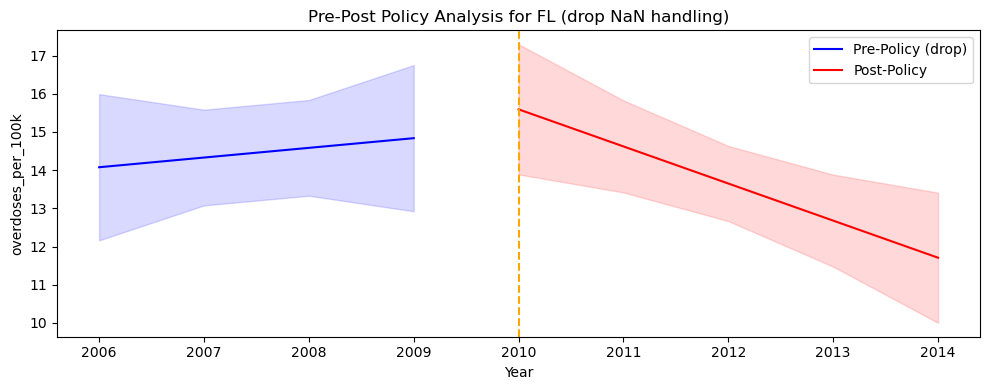

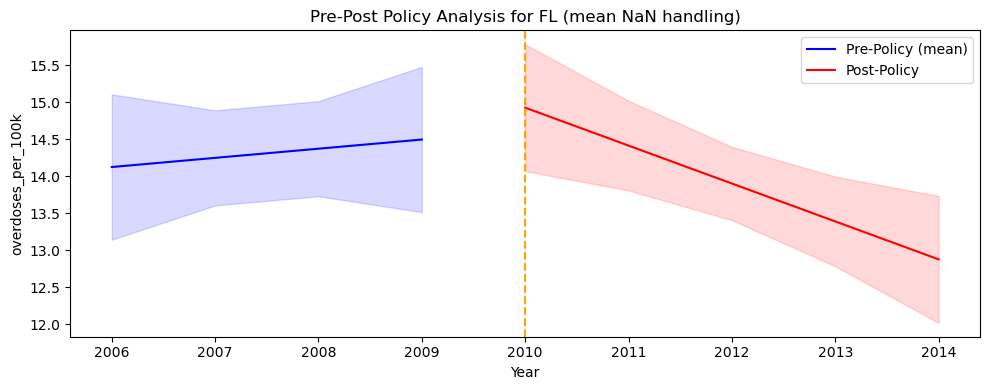

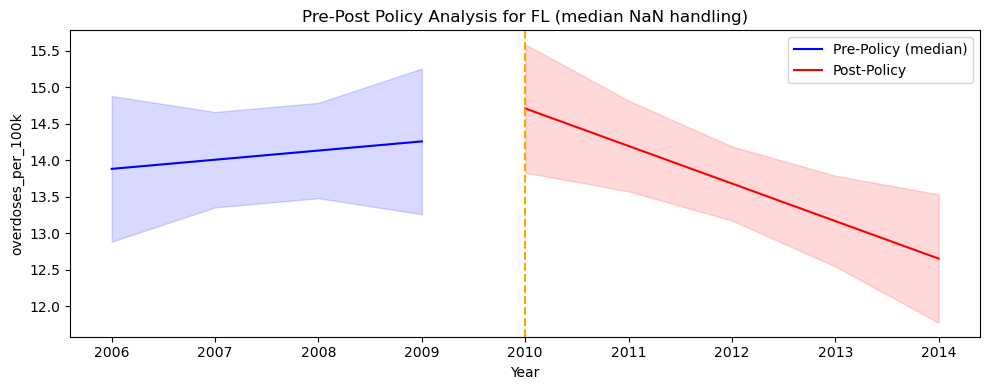

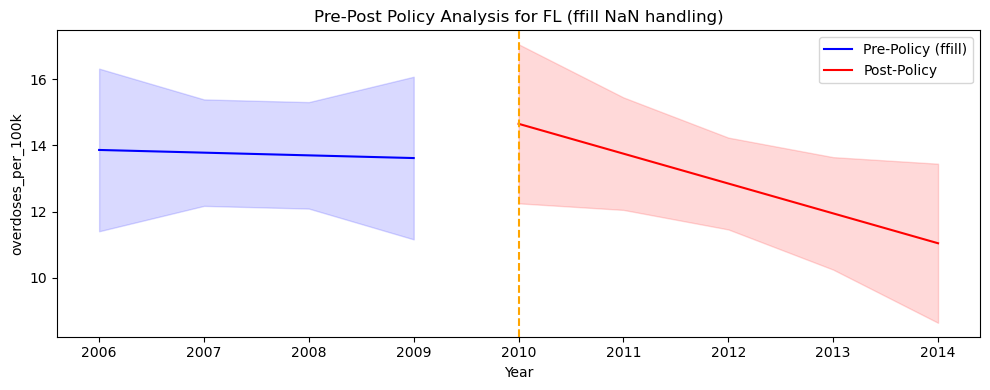

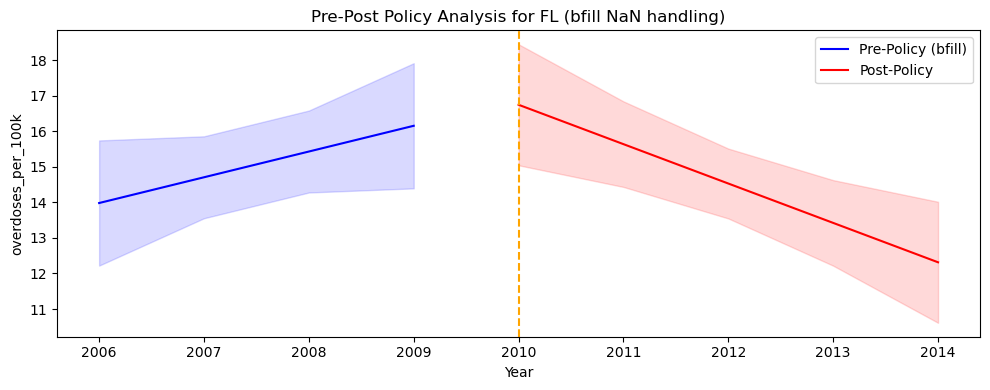

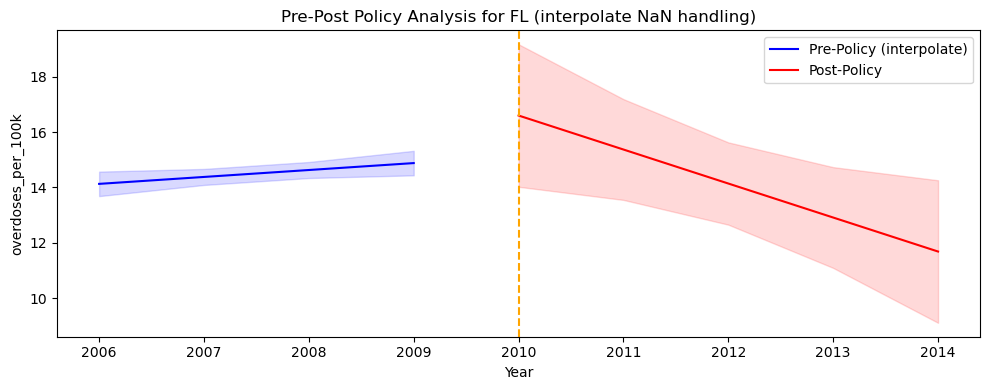

In [ ]:
# Florida
# 1. drop
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="drop"
)

# 2. mean
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="mean"
)

# 3. median
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="median"
)

# 4. ffill
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="ffill"
)

# 5. bfill
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="bfill"
)

# 6. interpolate
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="interpolate"
)

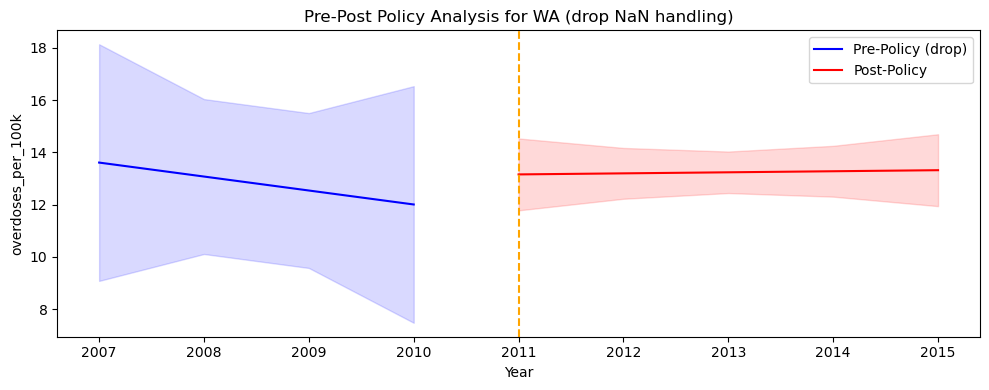

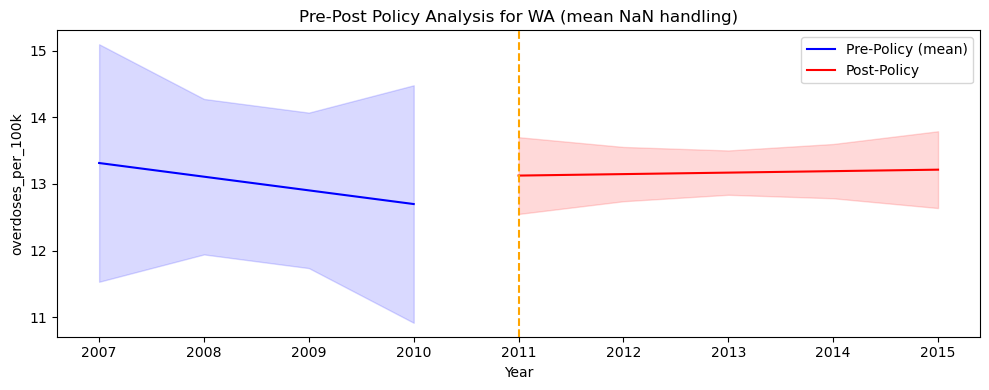

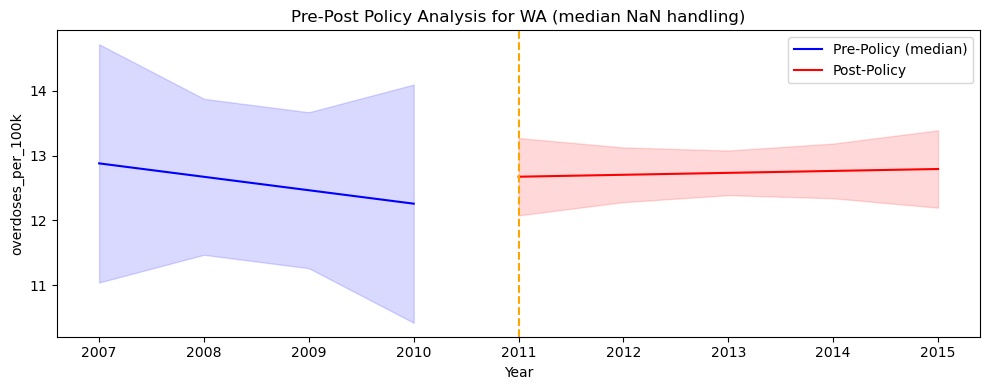

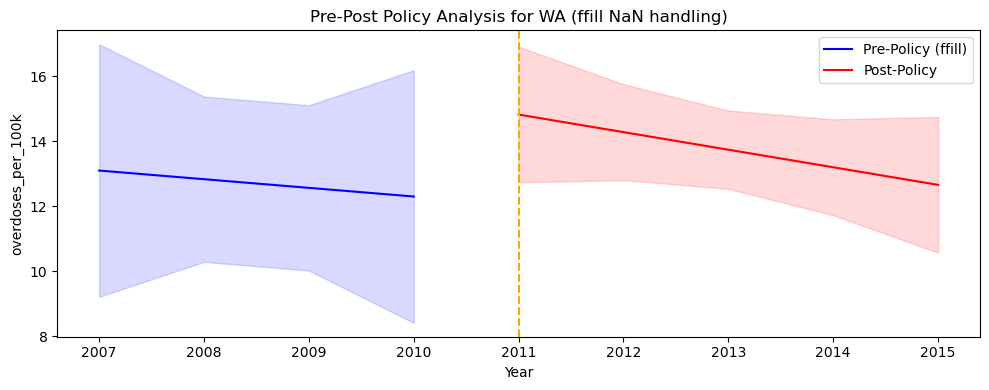

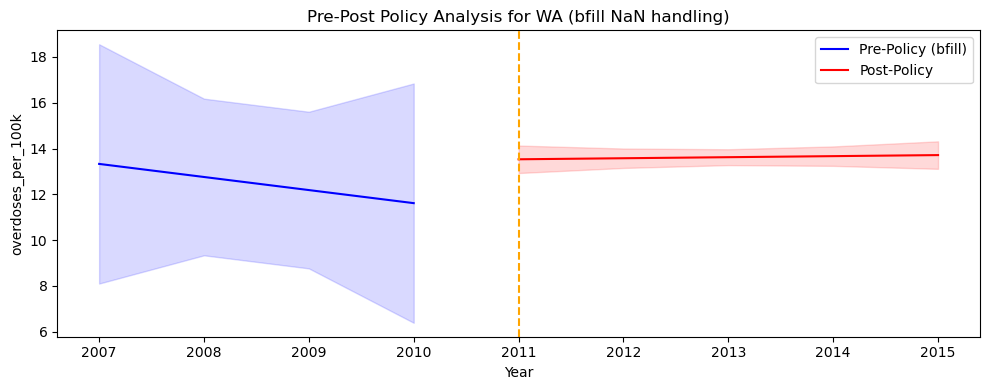

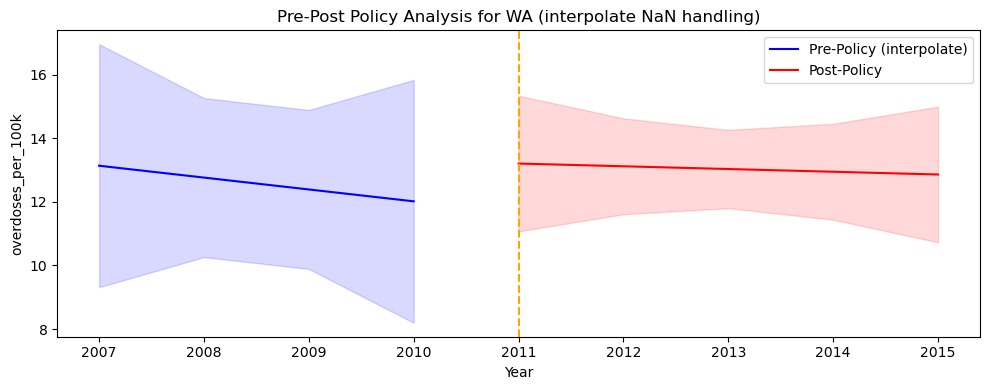

In [ ]:
# Washington
# 1. drop
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="drop"
)

# 2. mean
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="mean"
)

# 3. median
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="median"
)

# 4. ffill
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="ffill"
)

# 5. bfill
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="bfill"
)

# 6. interpolate
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="interpolate"
)

## 3. Compare different NaN value dealing ways (smaller plots)

In [30]:
import matplotlib.pyplot as plt


def plot_pre_post_grid(
    df,
    state_code,
    policy_year,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
):
    strategies = ["drop", "mean", "median", "ffill", "bfill", "interpolate"]

    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    axes = axes.flatten()

    # ensure y-scale consistent across all plots
    all_values = df[df["state"] == state_code][rate_col].dropna()
    y_min, y_max = all_values.min(), all_values.max()

    for i, strat in enumerate(strategies):
        ax = axes[i]

        # run the existing function but draw into ax instead of new figure
        df_state = df[df["state"] == state_code].copy()

        # ----- handle NaN -----
        if strat != "drop":
            df_state = df_state.sort_values("year")
            g = df_state.groupby("state")

            if strat == "mean":
                df_state[rate_col] = g[rate_col].transform(lambda s: s.fillna(s.mean()))
            elif strat == "median":
                df_state[rate_col] = g[rate_col].transform(
                    lambda s: s.fillna(s.median())
                )
            elif strat == "ffill":
                df_state[rate_col] = g[rate_col].transform(lambda s: s.ffill())
            elif strat == "bfill":
                df_state[rate_col] = g[rate_col].transform(lambda s: s.bfill())
            elif strat == "interpolate":
                df_state[rate_col] = g[rate_col].transform(lambda s: s.interpolate())

        # ----- aggregate to state-year -----
        state_year = (
            df_state.groupby("year", as_index=False)[rate_col]
            .mean()
            .rename(columns={rate_col: "rate"})
            .dropna(subset=["rate"])
        )

        # ----- split pre/post -----
        pre = state_year[
            (state_year["year"] >= policy_year - pre_window)
            & (state_year["year"] < policy_year)
        ]
        post = state_year[
            (state_year["year"] >= policy_year)
            & (state_year["year"] <= policy_year + post_window)
        ]

        # fit OLS helper
        def fit_segment(seg):
            X = sm.add_constant(seg["year"])
            m = sm.OLS(seg["rate"], X).fit()
            p = m.get_prediction(X)
            return p.predicted_mean, p.conf_int()[:, 0], p.conf_int()[:, 1]

        pre_mean, pre_low, pre_high = fit_segment(pre)
        post_mean, post_low, post_high = fit_segment(post)

        # ----- plot in the given axis -----
        ax.plot(pre["year"], pre_mean, color="blue")
        ax.fill_between(pre["year"], pre_low, pre_high, color="blue", alpha=0.15)

        ax.plot(post["year"], post_mean, color="red")
        ax.fill_between(post["year"], post_low, post_high, color="red", alpha=0.15)

        ax.axvline(policy_year, color="black", linestyle="--")

        ax.set_title(f"{strat}", fontsize=12)
        ax.set_ylim(y_min, y_max)  # same y-axis for comparability
        ax.set_xlabel("Year")
        ax.set_ylabel("Rate")

    fig.suptitle(f"{state_code}: Pre-Post Comparison (6 NaN Strategies)", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

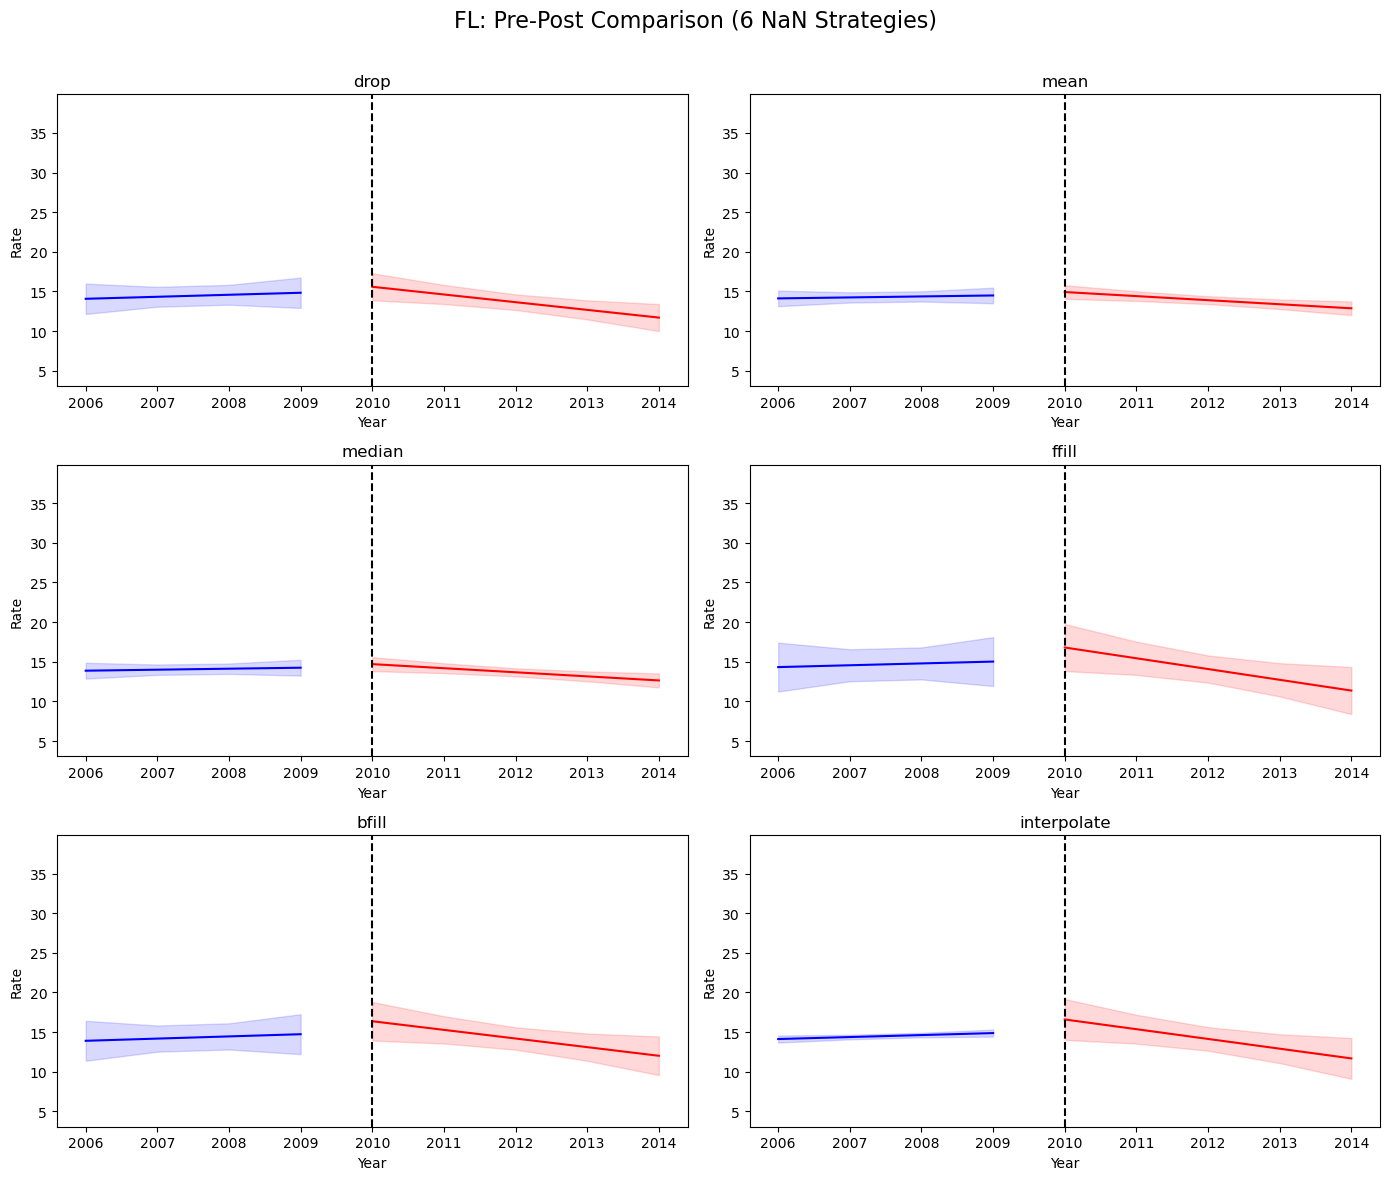

In [ ]:
# Florida
plot_pre_post_grid(df, "FL", 2010, rate_col="overdoses_per_100k")

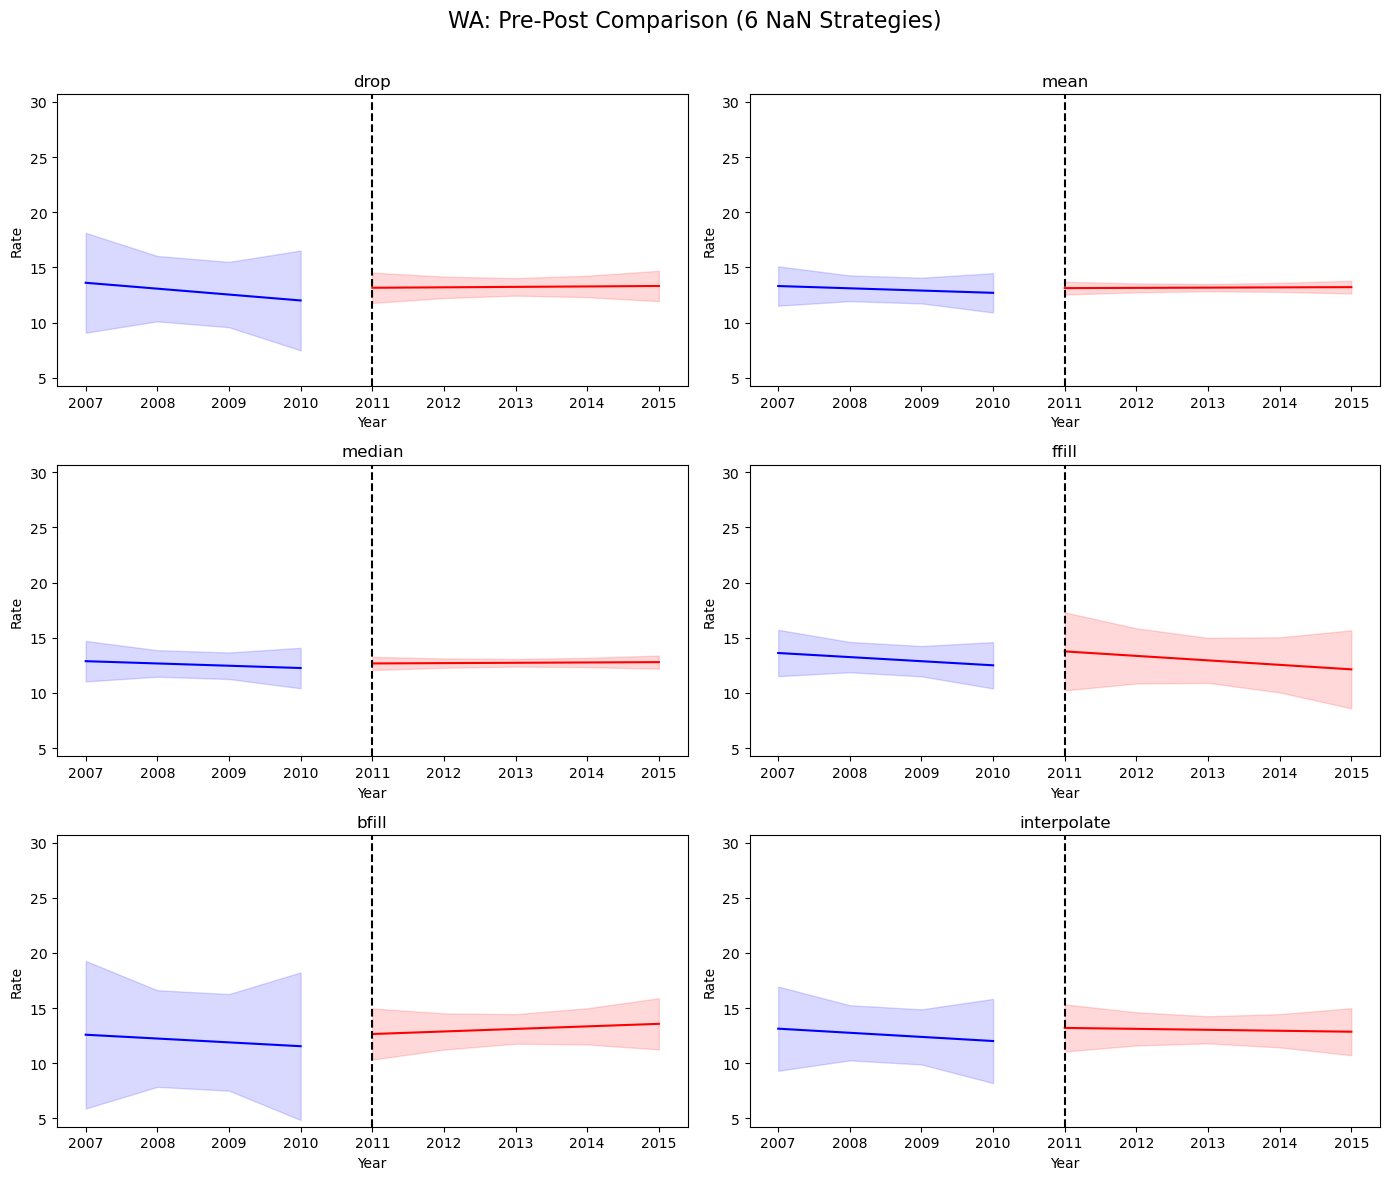

In [42]:
# Washington
plot_pre_post_grid(df, "WA", 2011, rate_col="overdoses_per_100k")

## 4. Final Result (for Mortality) (Pending now)

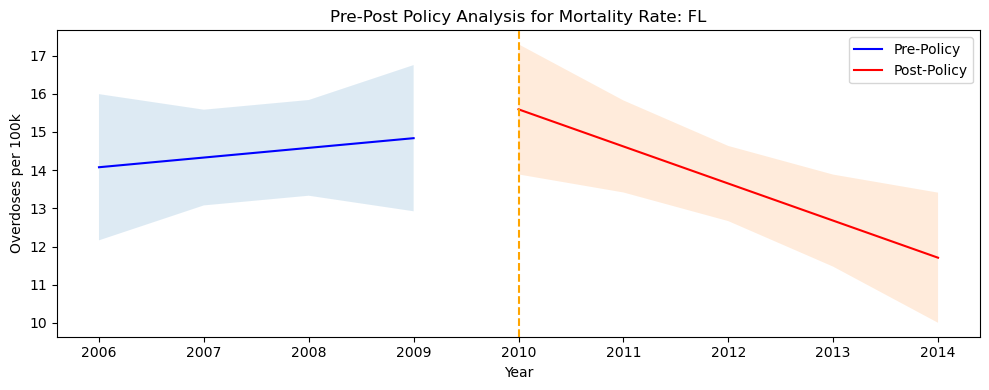

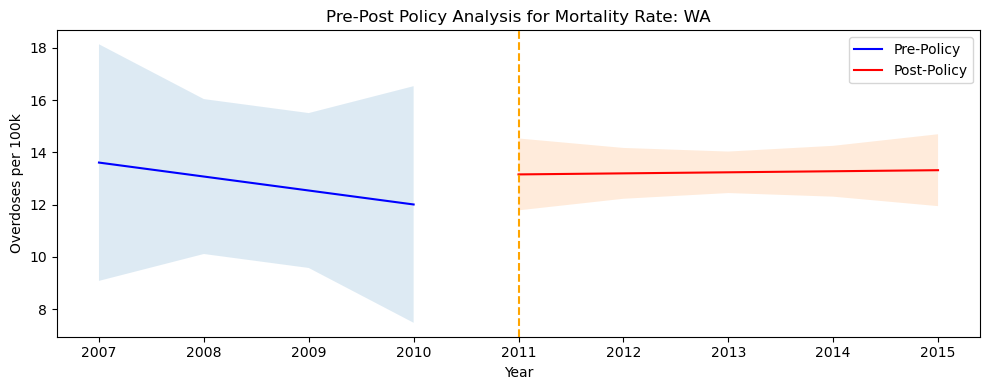

In [ ]:
# Florida: policy year 2010, use 2006–2009 vs 2010–2014
plot_pre_post_with_ci(
    df,
    state_code="FL",
    policy_year=2010,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
    state_label="FL",
)

# Washington: policy year 2011, use 2007–2010 vs 2011–2015
plot_pre_post_with_ci(
    df,
    state_code="WA",
    policy_year=2011,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
    state_label="WA",
)

###############################################################################################################

# Shipment part

## 1. Define plot functions (replace NaN value + plot)

In [47]:
def plot_pre_post_shipment(
    df,
    state_code,
    policy_year,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
    nan_strategy="drop",
):
    """
    Pre-Post plot for shipment (e.g., MME per capita) with linear trends and 95% CI.
    NaN strategies:
      - "drop": leave NaN as is (they will be dropped after aggregation)
      - "mean": fill NaN with the state-specific mean
      - "median": fill NaN with the state-specific median
      - "ffill": forward fill within each state (sorted by year)
      - "bfill": backward fill within each state (sorted by year)
      - "interpolate": linear interpolation within each state (sorted by year)
    """

    # Keep one state
    data = df[df["state"] == state_code].copy()

    # ---- NaN handling at raw-row level for this state ----
    if nan_strategy != "drop":
        data = data.sort_values("year")

        if nan_strategy == "mean":
            data[rate_col] = data[rate_col].fillna(data[rate_col].mean())
        elif nan_strategy == "median":
            data[rate_col] = data[rate_col].fillna(data[rate_col].median())
        elif nan_strategy == "ffill":
            data[rate_col] = data[rate_col].ffill()
        elif nan_strategy == "bfill":
            data[rate_col] = data[rate_col].bfill()
        elif nan_strategy == "interpolate":
            data[rate_col] = data[rate_col].interpolate(method="linear")
        else:
            raise ValueError("Invalid nan_strategy choice.")

    # Aggregate to state-year
    yearly = (
        data.groupby("year", as_index=False)[rate_col]
        .mean()
        .rename(columns={rate_col: "rate"})
        .dropna(subset=["rate"])
    )

    # Split into pre/post
    pre = yearly[
        (yearly["year"] >= policy_year - pre_window) & (yearly["year"] < policy_year)
    ]
    post = yearly[
        (yearly["year"] >= policy_year) & (yearly["year"] <= policy_year + post_window)
    ]

    if pre.empty or post.empty:
        print(
            f"Not enough data for {state_code} around {policy_year} ({nan_strategy})."
        )
        return

    # Fit regression with CI
    def fit_with_ci(seg):
        X = sm.add_constant(seg["year"])
        model = sm.OLS(seg["rate"], X).fit()
        pred = model.get_prediction(X)
        mean = pred.predicted_mean
        ci = pred.conf_int()
        return mean, ci[:, 0], ci[:, 1]

    pre_mean, pre_low, pre_high = fit_with_ci(pre)
    post_mean, post_low, post_high = fit_with_ci(post)

    # Plot
    plt.figure(figsize=(10, 4))

    # Pre-policy (red)
    plt.plot(
        pre["year"],
        pre_mean,
        color="red",
        label=f"Pre-Policy ({policy_year-pre_window}–{policy_year-1})",
    )
    plt.fill_between(pre["year"], pre_low, pre_high, color="red", alpha=0.15)

    # Post-policy (blue)
    plt.plot(
        post["year"],
        post_mean,
        color="blue",
        label=f"Post-Policy ({policy_year}–{policy_year+post_window})",
    )
    plt.fill_between(post["year"], post_low, post_high, color="blue", alpha=0.15)

    # Policy line
    plt.axvline(policy_year, color="black", linestyle="--")

    # Labels and title
    plt.title(
        f"Pre-Post Analysis for shipment ({rate_col}) - {state_code} [{nan_strategy}]"
    )
    plt.ylabel(rate_col)
    plt.xlabel("Year")

    plt.legend()
    plt.tight_layout()
    plt.show()

## 2. Compare different NaN value dealing ways (bigger plots)

In [ ]:
# Florida
# 1. drop
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="drop",
)

# 2. mean
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="mean",
)

# 3. median
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="median",
)

# 4. ffill
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="ffill",
)

# 5. bfill
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="bfill",
)

# 6. interpolate
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="interpolate",
)

Not enough data for FL around 2010 (drop).
Not enough data for FL around 2010 (mean).
Not enough data for FL around 2010 (median).
Not enough data for FL around 2010 (ffill).
Not enough data for FL around 2010 (bfill).
Not enough data for FL around 2010 (interpolate).


In [43]:
# Washington
# 1. drop
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="drop",
)

# 2. mean
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="mean",
)

# 3. median
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="median",
)

# 4. ffill
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="ffill",
)

# 5. bfill
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="bfill",
)

# 6. interpolate
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="interpolate",
)

Not enough data for WA around 2011 (drop).
Not enough data for WA around 2011 (mean).
Not enough data for WA around 2011 (median).
Not enough data for WA around 2011 (ffill).
Not enough data for WA around 2011 (bfill).
Not enough data for WA around 2011 (interpolate).


## 3. Compare different NaN value dealing ways (smaller plots)

In [37]:
def plot_pre_post_shipment_grid(
    df,
    state_code,
    policy_year,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
):
    """
    Draw 6 pre-post shipment plots (one for each NaN strategy) in a 3x2 grid.
    """

    strategies = ["drop", "mean", "median", "ffill", "bfill", "interpolate"]

    # restrict to this state for y-axis scale
    data_all = df[df["state"] == state_code].copy()
    all_vals = data_all[rate_col].dropna()
    y_min, y_max = all_vals.min(), all_vals.max()

    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    axes = axes.flatten()

    for i, strat in enumerate(strategies):
        ax = axes[i]

        data = data_all.copy()

        # ----- NaN handling -----
        if strat != "drop":
            data = data.sort_values("year")
            if strat == "mean":
                data[rate_col] = data[rate_col].fillna(data[rate_col].mean())
            elif strat == "median":
                data[rate_col] = data[rate_col].fillna(data[rate_col].median())
            elif strat == "ffill":
                data[rate_col] = data[rate_col].ffill()
            elif strat == "bfill":
                data[rate_col] = data[rate_col].bfill()
            elif strat == "interpolate":
                data[rate_col] = data[rate_col].interpolate(method="linear")

        # Aggregate to state-year
        yearly = (
            data.groupby("year", as_index=False)[rate_col]
            .mean()
            .rename(columns={rate_col: "rate"})
            .dropna(subset=["rate"])
        )

        # Split pre/post
        pre = yearly[
            (yearly["year"] >= policy_year - pre_window)
            & (yearly["year"] < policy_year)
        ]
        post = yearly[
            (yearly["year"] >= policy_year)
            & (yearly["year"] <= policy_year + post_window)
        ]

        if pre.empty or post.empty:
            ax.set_title(f"{strat} (not enough data)")
            ax.axis("off")
            continue

        # Fit regression with CI
        def fit_with_ci(seg):
            X = sm.add_constant(seg["year"])
            model = sm.OLS(seg["rate"], X).fit()
            pred = model.get_prediction(X)
            mean = pred.predicted_mean
            ci = pred.conf_int()
            return mean, ci[:, 0], ci[:, 1]

        pre_mean, pre_low, pre_high = fit_with_ci(pre)
        post_mean, post_low, post_high = fit_with_ci(post)

        # Plot on this axis
        ax.plot(
            pre["year"],
            pre_mean,
            color="red",
        )
        ax.fill_between(pre["year"], pre_low, pre_high, color="red", alpha=0.15)

        ax.plot(
            post["year"],
            post_mean,
            color="blue",
        )
        ax.fill_between(post["year"], post_low, post_high, color="blue", alpha=0.15)

        ax.axvline(policy_year, color="black", linestyle="--")

        ax.set_title(strat, fontsize=11)
        ax.set_ylim(y_min, y_max)
        ax.set_xlabel("Year")
        ax.set_ylabel(rate_col)

    fig.suptitle(
        f"{state_code} shipment pre-post ({rate_col}) — 6 NaN strategies", fontsize=16
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

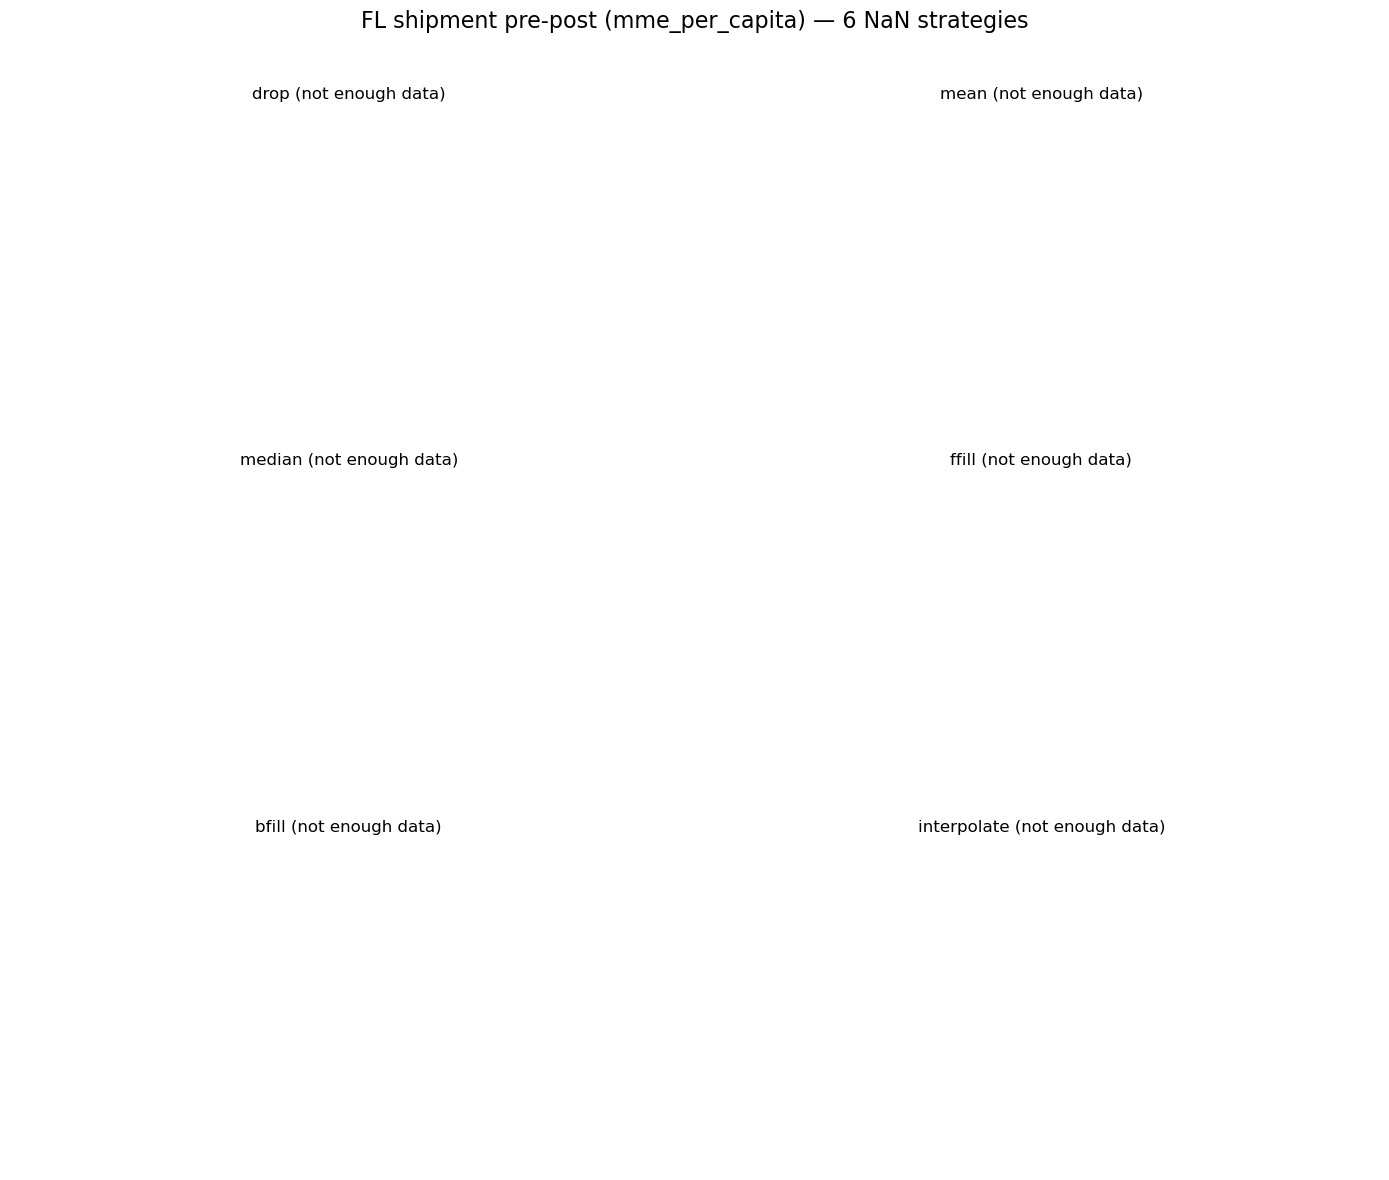

In [38]:
# Florida
plot_pre_post_shipment_grid(
    df,
    state_code="FL",
    policy_year=2010,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
)

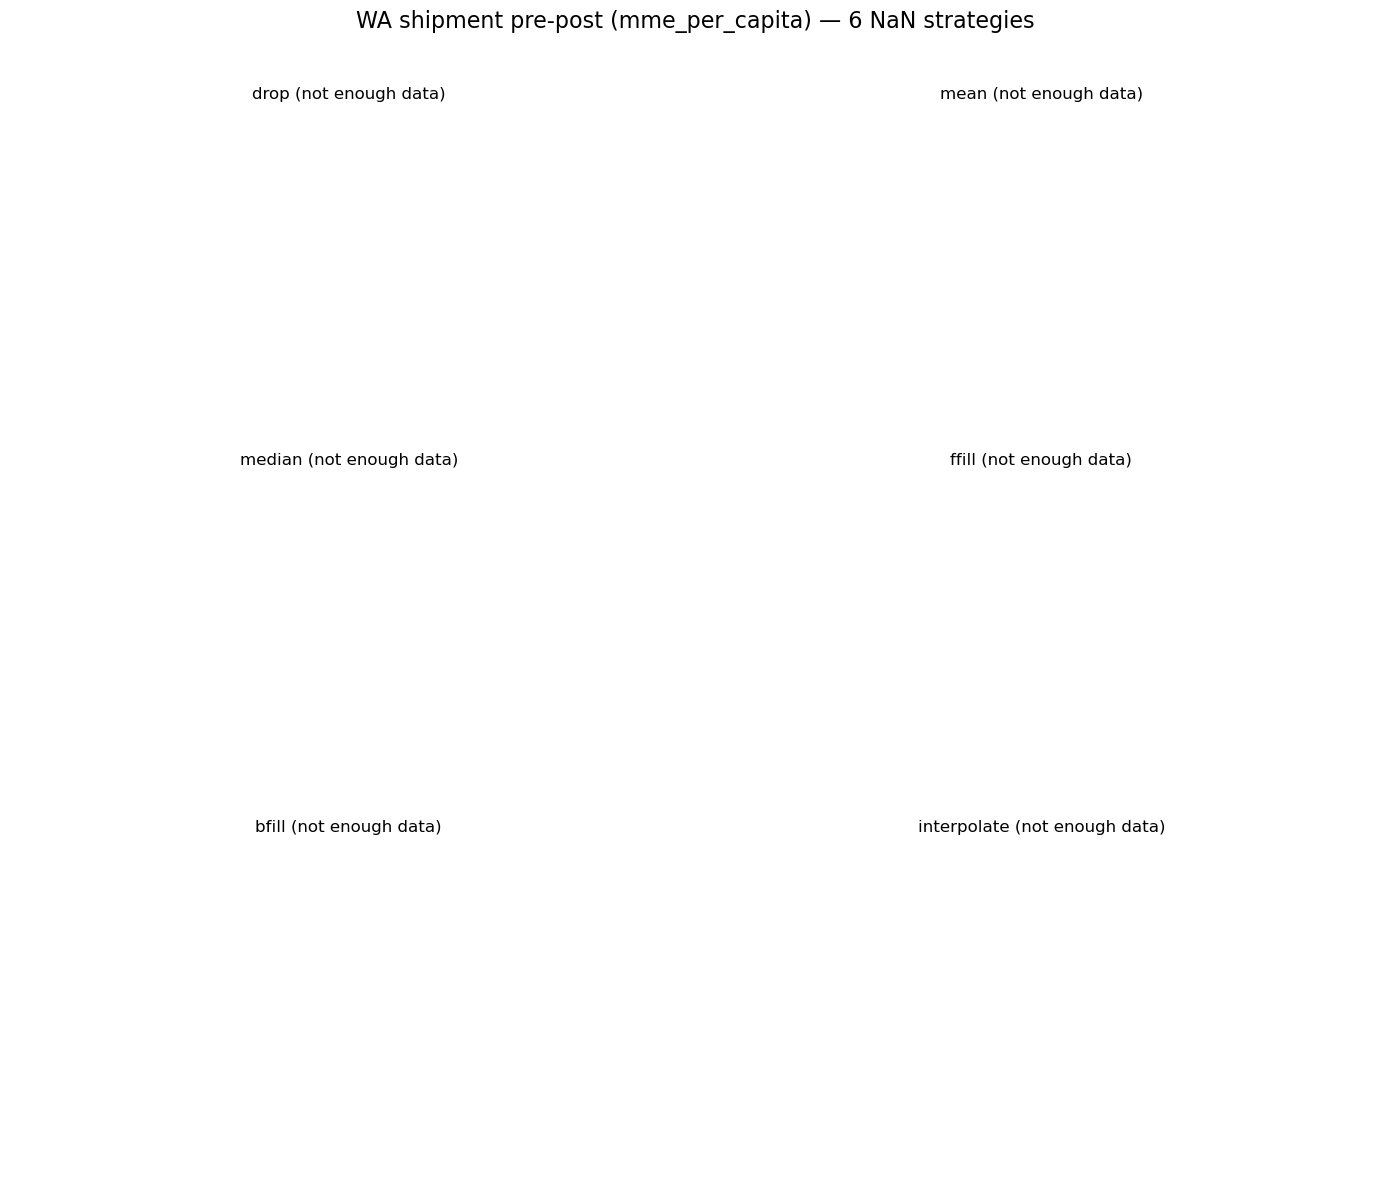

In [39]:
# Washington
plot_pre_post_shipment_grid(
    df,
    state_code="WA",
    policy_year=2011,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
)

## 4. Final Result (for Shipment) (Pending now)